In [1]:
import jax.numpy as jnp
from typing import Optional
import matplotlib.pyplot as plt
import numpy.random as nr
import numpy as np
import jax
import haiku as hk

In [20]:
class DisBase():
    def __init__(self, 
                 dim: int = 1,
                 value: int = 10) -> None:
        self.rng_seq = hk.PRNGSequence(value)
        self.dim = dim

class student_t(DisBase):
    def __init__(self, dim: int = 1, value: int = 10, df: int = 3) -> None:
        super().__init__(dim, value)
        self.df = df

    def sampler(self, *args): #args: 0 loc 1 scale 2 number
        epsilon = jax.random.normal(next(self.rng_seq), shape = [self.dim, args[2]])
        y = args[1] @ epsilon
        u = jnp.sqrt(self.df / nr.chisquare(self.df))
        x = u * y + args[0].reshape((self.dim,1))
        return x.T, epsilon.T

    def logpdf(self, *args): #args: 0 data 1 loc 2 scale
        v = (args[0] - args[1]) / args[2]
        logp = - 0.5 * (self.df + self.dim) * jnp.log(1 + v * v / self.df)
        return logp

class multivariate_normal(DisBase):
    def __init__(self, dim: int = 100, value: int = 10) -> None:
        super().__init__(dim, value)
    
    def sampler(self, *args): #args: 0 loc 1 scale 2 number , 3 beta
        epsilon = jax.random.normal(next(self.rng_seq), shape = [self.dim, args[2]])
        x = args[1] @ epsilon + args[0].reshape((self.dim,1))
        return x.T, epsilon.T
    
    def logpdf(self, *args): #args: 0 data 1 loc 2 scale
        v = (args[0] - args[1]) / args[2]
        logp = - 0.5 * v * v
        return logp

In [21]:
class Basic_settings():
    def __init__(
        self,
        target_str: str = 'multivariate_normal',      #target distribution
        proposal_str: str = 'multivariate_normal',     #proposal distribution
        itrnum: int = 10000,                #number of MH steps
        dim : int = 1,                  #dimensions
        df : Optional[float] = 3,             #degree of freedom of student_t
        value : int = 10
        ) -> None:
        self.target_str = target_str
        self.proposal_str = proposal_str
        self.itrnum = itrnum
        self.dim = dim
        self.df = df
        if self.target_str == 'multivariate_normal':
            self.target = multivariate_normal(self.dim, value)
        else:
            NotImplementedError

        if self.proposal_str == 'multivariate_normal':
            self.proposal = multivariate_normal(self.dim, value)
        elif self.proposal_str == 'student_t':
            self.proposal = student_t(self.dim, self.df)
            self.proposal_adp = multivariate_normal(self.dim)
            self.tcoeff = self.df / (self.df - 2)
        else:
            NotImplementedError
            
        self.logtarget = jax.jit(self.target.logpdf)
        self.logproposal = jax.jit(self.proposal.logpdf)
    
    # t_mean: mean value of target ; t_L: scale of target
    # p_mean: mean value of proposal ; p_L: scale of proposal
    # adp_L: scale of distribution used for adaptation. adp_mean = p_mean due to moment matching
    def set_distribution_parameters(self, *args) -> None:
        self.t_mean = args[0]
        self.t_L = args[1]

        self.p_mean = args[2]
        self.p_L = args[3]

        if self.proposal_str == 'student_t':
            self.adp_L = self.p_L * jnp.sqrt(self.tcoeff) #scale of normal after moment matching
        elif self.proposal_str == 'multivariate_normal':
            self.adp_L = self.p_L

    def init_state(self) -> None:
        self.x0, _ = self.proposal.sampler(self.p_mean, self.p_L, 1)
        self.current = self.x0.reshape((self.dim,))
        self.log_t = self.logtarget(self.current, self.t_mean, self.t_L)
        self.log_p = self.logproposal(self.current, self.p_mean, self.p_L)

    def IMHsampling(self, num):
        sample_p, epsilon = self.proposal.sampler(self.p_mean, self.p_L, num)
        return sample_p, epsilon

    def IMHstep(self, p_test):
        is_accept = 0
        log_t_new = self.logtarget(p_test, self.t_mean, self.t_L)
        log_p_new = self.logproposal(p_test, self.p_mean, self.p_L)
        ratio_t = log_t_new - self.log_t
        ratio_p = log_p_new - self.log_p
        accept_ratio = min(1.0, jnp.exp(ratio_t - ratio_p))
        test_uniform = nr.uniform(0.0, 1.0, 1)
        if test_uniform <= accept_ratio:
            self.current = p_test
            is_accept = 1
            self.log_t = log_t_new
            self.log_p = log_p_new
        return accept_ratio, is_accept
    
class IndMH(Basic_settings):
    def __init__(self,
        target_str: str = 'stochastic_volatility',
        proposal_str: str = 'multivariate_normal',
        itrnum: int = 10000,
        dim : int = 16,
        df : Optional[float] = 3,
        value : int = 10
        ):
        super().__init__(target_str, proposal_str, itrnum, dim, df, value)
    
    
    def IMH(self):
       #initialize arrays
        t_sample = np.zeros((self.itrnum, self.dim))
        acceptance_rate = np.zeros(self.itrnum)
        is_acc = np.zeros(self.itrnum)

        self.init_state()
        #IMH iterations
        p_sample , _= self.IMHsampling(self.itrnum)
        for i in range(self.itrnum):
                
            a, is_a = self.IMHstep(p_sample[i])          

            #update
            t_sample[i] = self.current.reshape((self.dim,))
            acceptance_rate[i] = np.reshape(a,())
            is_acc[i] = is_a

        return t_sample, p_sample, acceptance_rate, is_acc

In [22]:
class Estimator():
    def __init__(self, sample_size) -> None:
        self.sample_size = sample_size

    def F(self):
        raise NotImplementedError

    def F_approx(self):
        raise NotImplementedError
    
    def analytics(self):
        raise NotImplementedError
    
    def sample_loader(self, X, Y, Acpt, para):
        self.X = X[-self.sample_size:]
        self.Y = Y[-self.sample_size:]
        self.Acpt = Acpt[-self.sample_size:]
        self.param = para
    
    def IMCV(self):
        Main = self.F(self.X)
        Poisson_cv = self.Acpt * (self.F(self.Y) - self.F(self.X))
        Static_cv = self.F(self.Y) - self.param
        IMH_estimator = Main + Poisson_cv - Static_cv
        return IMH_estimator.mean(), IMH_estimator.var()

class Simulation_Est(Estimator):
    def __init__(self, sample_size) -> None:
        super().__init__(sample_size)
    
    def F(self, data):
        return data
    
    def F_approx(self, data):
        return data
    
    def analytics(self, data):
        return data

    def cmc(self, data):
        return data.mean(), data.var()

In [23]:
epoch = 100                   # Number of estimator replications
Itr = 6000                     # Number of iterations of MCMC
N = 5000                        # Number of Samples taken from MCMC
d = 1
df = 3
step = 6

distribution1 = "multivariate_normal"
distribution2 = "student_t"


t_mean = 0
t_mean = np.array([t_mean])
p_mean = 0
p_mean = np.array([p_mean])
t_scale = 1
t_scale = np.array([t_scale])
p_scale = 1.8
p_scale = np.array([p_scale])

In [24]:
imhcv_means = np.zeros((step,epoch))
cmc_means = np.zeros((step, epoch))
vrfc = np.zeros(step)
varlist = np.zeros(step)
p_list = np.zeros(step)
for k in range(step):
    print(k,"th data")
    p_list[k] = p_scale
    for i in range(epoch):
        IMH = IndMH(distribution1, distribution1, Itr, d, df, 10+i)
        IMH.set_distribution_parameters(t_mean,t_scale,p_mean,p_scale)
        IMH.init_state()
        x,y,acc,isacc = IMH.IMH()
        est = Simulation_Est(5000)
        est.sample_loader(x,y,acc,p_mean)
        imcv = est.IMCV()
        cmcdata = nr.normal(t_mean, t_scale, N)
        imhcv_means[k,i] = imcv[0]
        cmc_means[k,i] = cmcdata.mean()
        if (i+1) % 10 == 0:
            print(i+1,"th epoch")
    vrfc[k] = cmc_means[k].var()/imhcv_means[k].var()
    varlist[k] = imhcv_means[k].var()
    p_scale = p_scale - 0.1

0 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
1 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
2 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
3 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
4 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch
5 th data
10 th epoch
20 th epoch
30 th epoch
40 th epoch
50 th epoch
60 th epoch
70 th epoch
80 th epoch
90 th epoch
100 th epoch


[ 2.3627851   5.42164611  8.41793963 17.21358839 21.21360821 43.44086488]
[1.8 1.7 1.6 1.5 1.4 1.3]
(6, 100)


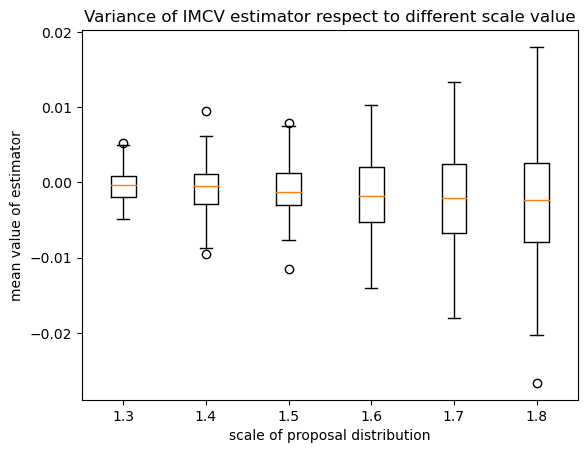

In [34]:
print(vrfc)
label = [str(np.around(p_list[i],2)) for i in range(step)]
label = label[::-1]
print(p_list)
print(imhcv_means.shape)
plt.boxplot(imhcv_means[::-1,:].T, labels=label, widths=0.3)
plt.title('Variance of IMCV estimator respect to different scale value')
plt.xlabel('scale of proposal distribution')
plt.ylabel('mean value of estimator')
plt.show()

In [26]:
def func(x,y,s):
    a=(np.exp(-(1-1/(s**2))*(y**2-x**2)/2)-1)**2
    b=(y -x)**2
    c=((2*s**2/(np.sqrt(2*np.pi)*s))*np.exp(-y**2/(2*s**2))-(1/(np.sqrt(2*np.pi))*np.exp(-x**2/2)))
    d=(1/(np.sqrt(2*np.pi)*s))*np.exp(-y**2/(2*s**2))
    resul = a*b*c*d
    return resul

s=1.4
N0=10000000
bound = np.zeros(step)
for i in range(step):
    print(i)
    x = nr.normal(0,1,N0)
    y= nr.normal(0,s,N0)
    bound[i] = 1/func(x,y,s).mean()
    s=s-0.05

print(bound)


0
1
2
3
4
5
[0.17135098 0.32418494 0.78641782 1.72441009 3.70023105 9.09988978]


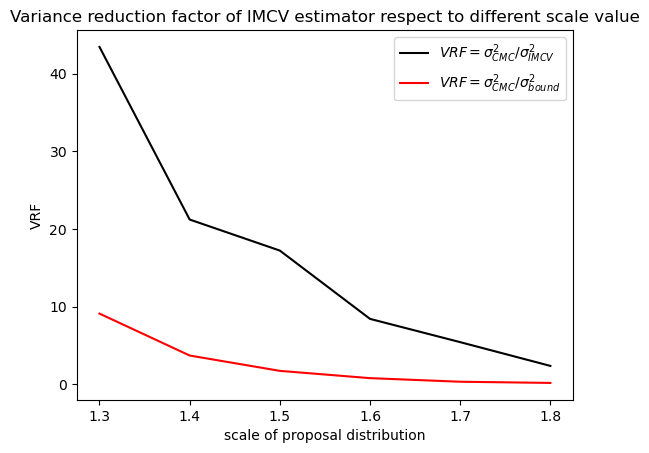

In [35]:
plt.plot(p_list, vrfc,c = 'black')
plt.plot(p_list, bound,c = 'r')
plt.legend(['$VRF=\sigma^2_{CMC}/\sigma^2_{IMCV}$','$VRF=\sigma^2_{CMC}/\sigma^2_{bound}$','$VRF=1$']) 
plt.xlabel('scale of proposal distribution')
plt.ylabel('VRF')
plt.title('Variance reduction factor of IMCV estimator respect to different scale value')
plt.show()

In [5]:
import scipy.stats as ss

print(1-ss.norm.cdf(6.5,11.74,3.5))

0.9328219548640079


[3.51349256e-04 3.06936174e-01 7.08287603e-01 1.38621581e+00
 5.80881455e+00]


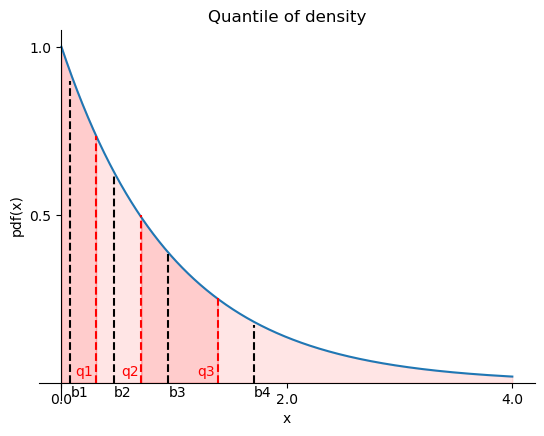

In [29]:
import scipy.stats as ss
import numpy as np
import matplotlib.pyplot as plt
import numpy.random as nr
num = 5
X = np.linspace(0, 4, 1000)
Y = ss.expon.pdf(X, 0, 1)
S = nr.exponential(1, 1000)
plt.plot(X, Y)
approx = np.linspace(0, 1, num)
obj = np.quantile(S, approx)
plt.xticks(np.array([-0,2,4]), (0.0,2.0,4.0))
plt.yticks(np.array([0.5,1.0]), (0.5,1.0))
print(obj)
for i in range(num-1):
    if i >=1:
        plt.axvline(obj[i], c='r', ls='--',  ymax = ss.expon.pdf(obj[i], 0, 1.09)+0.02,ymin=0.045,label = 'q'+str(i+1))
        plt.text(obj[i]-0.18,0.02,'q'+str(i), color = 'r')
    plt.axvline(obj[i]+0.08*(i+1), c='black', ls='--',  ymax = ss.expon.pdf(obj[i]+0.08*(i+1), 0, 1.09)+0.01, ymin=0.045,label = 'b'+str(i+1))
    plt.text(obj[i]+(0.08*i)+0.08,-0.04,'b'+str(i+1), color = 'black')
    if i%2 == 0:
        plt.fill_between(np.linspace(obj[i], obj[i+1], 1000), ss.expon.pdf(np.linspace(obj[i], obj[i+1], 1000), 0, 1), color='red', alpha=0.2)
    elif i == 3:
        plt.fill_between(np.linspace(obj[i], 4, 1000), ss.expon.pdf(np.linspace(obj[i], 4, 1000), 0, 1), color='red',alpha=0.1)
    else:
        plt.fill_between(np.linspace(obj[i], obj[i+1], 1000), ss.expon.pdf(np.linspace(obj[i], obj[i+1], 1000), 0, 1), color='red', alpha=0.1)


plt.xlabel("x")
plt.ylabel("pdf(x)")
plt.title( "Quantile of density")
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.spines['bottom'].set_position(('data',0))
ax.spines['left'].set_position(('data',0))


plt.show()